# Introduction

In this notebook we test performance of ABC on basic linear regression problem.

We explore all possible method configurations.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from pygom.inference.fitting_problem_spec import Unknown
from pygom.inference.priors import UniformPrior

from pygom.inference.approximate_bayesian_computation.abc import ABC

# 1) Generate data

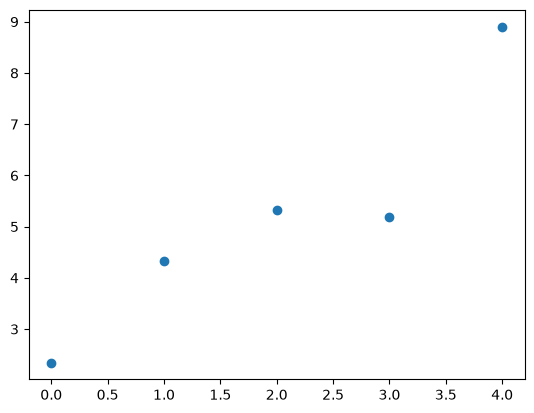

In [2]:
rng = np.random.default_rng(1)

# Parameters
grad = 1.5
inter = 2.0
sd = 1.0
target_params = [grad, inter, sd]

# Synthetic data
x_dat = np.arange(0, 5, 1)
y_dat = grad * x_dat + inter
y_dat += rng.normal(0, sd, size=len(y_dat))

# Plot
plt.scatter(x_dat, y_dat)
plt.show()

# 2) Define objective function

In [3]:
def objective(theta):

    y_sim = x_dat * theta[0] + theta[1]

    y_sim += rng.normal(0, theta[2], size=len(y_sim))

    diff2 = (y_sim - y_dat)**2

    return np.sqrt(diff2.mean())

#3) Define unknowns

In [4]:
gradient = Unknown(
    id='grad',
    prior=UniformPrior(0, 3)
)

intercept = Unknown(
    id='inter',
    prior=UniformPrior(0, 5)
)

sigma = Unknown(
    id='inter',
    lower=0,
    upper=5,
    prior=UniformPrior(0, 5)
)

unknowns = [gradient, intercept, sigma]

# Run different methods:

## Global covariance

Generation: 0
Tolerance: inf
Accepted: 128 / 128 (100.0%)
Rejected (outside allowed limits): 0 / 128 (0.0%)
Rejected (above distance tolerance): 0 / 128 (0.0%)
ESS: 100.00000000000006
Time taken: 1.7564332485198975 seconds


Generation: 1
Tolerance: 3.5532890606848984
Accepted: 104 / 400 (26.0%)
Rejected (outside allowed limits): 208 / 400 (52.0%)
Rejected (above distance tolerance): 88 / 192 (45.8%)
ESS: 81.70243951028782
Time taken: 1.777247667312622 seconds


Generation: 2
Tolerance: 2.329822716433194
Accepted: 107 / 468 (22.9%)
Rejected (outside allowed limits): 180 / 468 (38.5%)
Rejected (above distance tolerance): 181 / 288 (62.8%)
ESS: 88.40768390458048
Time taken: 2.0168449878692627 seconds


Generation: 3
Tolerance: 1.6060404334406235
Accepted: 125 / 678 (18.4%)
Rejected (outside allowed limits): 198 / 678 (29.2%)
Rejected (above distance tolerance): 355 / 480 (74.0%)
ESS: 88.23050216771593
Time taken: 2.515289068222046 seconds


Generation: 4
Tolerance: 1.2779077481114411
Acc

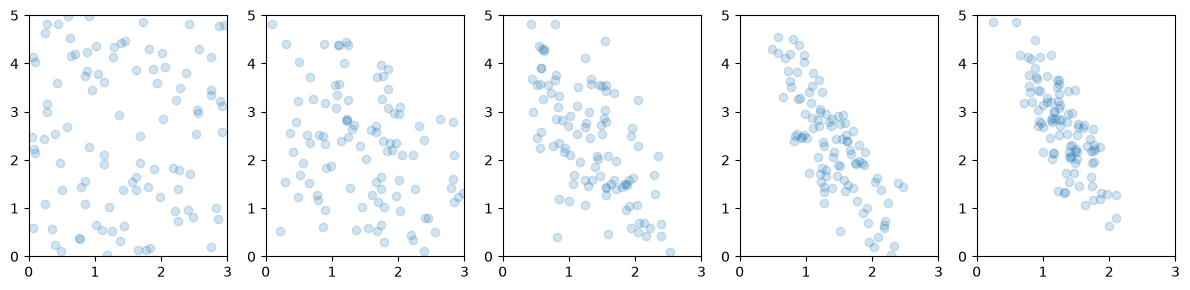

In [5]:
abc = ABC(
        n_particles=100,
        quantile=0.5,
        initial_tolerance=np.inf,
        max_attempts=1_000_000,
        covariance_method="global",
        rng=rng
    )

fit = abc.refine_posterior(
    objective=objective,
    unknowns=unknowns,
    n_generations=5
)

fig, axes = plt.subplots(1, 5, figsize=(12,3))

axes = axes.flatten()

for ax, res in zip(axes, fit):
    ax.scatter(res.population.particles[:, 0], res.population.particles[:, 1], alpha=0.2)
    ax.set_xlim(0, 3)
    ax.set_ylim(0, 5)
plt.tight_layout()
plt.show()

## Local covariance

Generation: 0
Tolerance: inf
Accepted: 128 / 128 (100.0%)
Rejected (outside allowed limits): 0 / 128 (0.0%)
Rejected (above distance tolerance): 0 / 128 (0.0%)
ESS: 100.00000000000006
Time taken: 0.415118932723999 seconds


Generation: 1
Tolerance: 3.4898662176117323
Accepted: 119 / 330 (36.1%)
Rejected (outside allowed limits): 170 / 330 (51.5%)
Rejected (above distance tolerance): 41 / 160 (25.6%)
ESS: 91.63111728503812
Time taken: 1.5653674602508545 seconds


Generation: 2
Tolerance: 2.425457955784195
Accepted: 108 / 313 (34.5%)
Rejected (outside allowed limits): 121 / 313 (38.7%)
Rejected (above distance tolerance): 84 / 192 (43.8%)
ESS: 90.17894225582977
Time taken: 1.499108076095581 seconds


Generation: 3
Tolerance: 1.7070774521304597
Accepted: 117 / 403 (29.0%)
Rejected (outside allowed limits): 147 / 403 (36.5%)
Rejected (above distance tolerance): 139 / 256 (54.3%)
ESS: 91.91594708746982
Time taken: 1.9298813343048096 seconds


Generation: 4
Tolerance: 1.3070393432910787
Acce

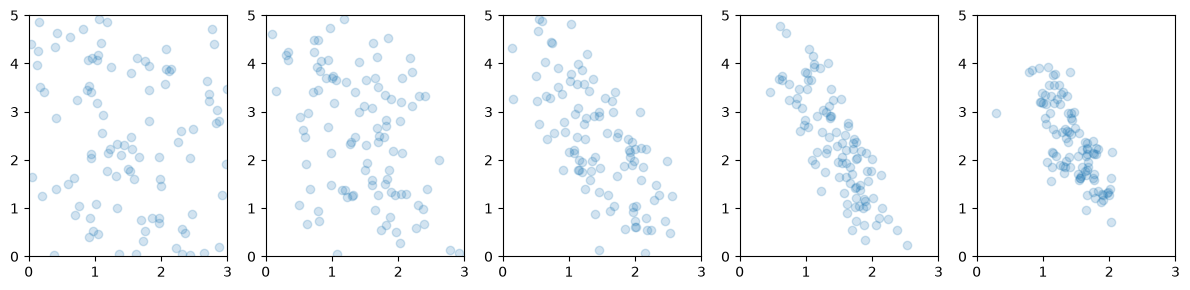

In [6]:
abc = ABC(
        n_particles=100,
        quantile=0.5,
        initial_tolerance=np.inf,
        max_attempts=1_000_000,
        covariance_method="local",
        rng=rng
    )

fit = abc.refine_posterior(
    objective=objective,
    unknowns=unknowns,
    n_generations=5
)

fig, axes = plt.subplots(1, 5, figsize=(12,3))

axes = axes.flatten()

for ax, res in zip(axes, fit):
    ax.scatter(res.population.particles[:, 0], res.population.particles[:, 1], alpha=0.2)
    ax.set_xlim(0, 3)
    ax.set_ylim(0, 5)
plt.tight_layout()
plt.show()

## Nearest neighbour covariance

### Euclidean distance

Generation: 0
Tolerance: inf
Accepted: 128 / 128 (100.0%)
Rejected (outside allowed limits): 0 / 128 (0.0%)
Rejected (above distance tolerance): 0 / 128 (0.0%)
ESS: 100.00000000000006
Time taken: 0.32756710052490234 seconds


Generation: 1
Tolerance: 3.2797181077905493
Accepted: 103 / 313 (32.9%)
Rejected (outside allowed limits): 121 / 313 (38.7%)
Rejected (above distance tolerance): 89 / 192 (46.4%)
ESS: 84.08899542864833
Time taken: 1.4434318542480469 seconds


Generation: 2
Tolerance: 2.299954878824985
Accepted: 102 / 297 (34.3%)
Rejected (outside allowed limits): 73 / 297 (24.6%)
Rejected (above distance tolerance): 122 / 224 (54.5%)
ESS: 70.86036793417466
Time taken: 1.6300203800201416 seconds


Generation: 3
Tolerance: 1.7214829897511508
Accepted: 117 / 459 (25.5%)
Rejected (outside allowed limits): 107 / 459 (23.3%)
Rejected (above distance tolerance): 235 / 352 (66.8%)
ESS: 52.98419819477308
Time taken: 1.9816431999206543 seconds


Generation: 4
Tolerance: 1.3943955545920146
A

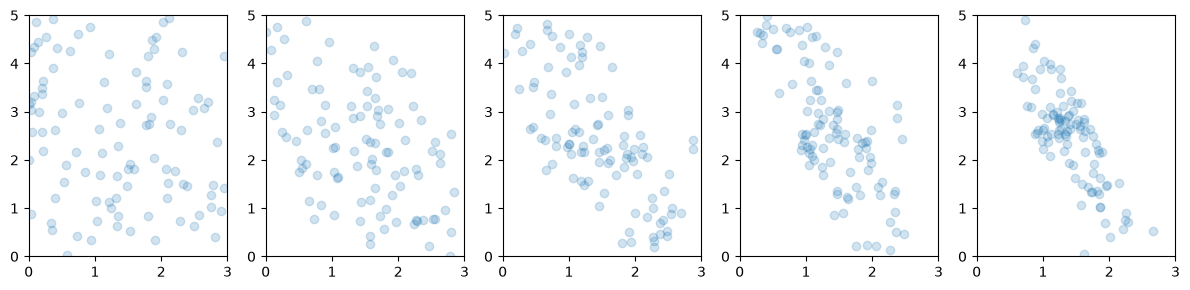

In [7]:
abc = ABC(
        n_particles=100,
        quantile=0.5,
        initial_tolerance=np.inf,
        max_attempts=1_000_000,
        covariance_method="knn",
        distance_method="euclidean",
        k=20,
        rng=rng
    )

fit = abc.refine_posterior(
    objective=objective,
    unknowns=unknowns,
    n_generations=5
)

fig, axes = plt.subplots(1, 5, figsize=(12,3))

axes = axes.flatten()

for ax, res in zip(axes, fit):
    ax.scatter(res.population.particles[:, 0], res.population.particles[:, 1], alpha=0.2)
    ax.set_xlim(0, 3)
    ax.set_ylim(0, 5)
plt.tight_layout()
plt.show()

## Nearest neighbour covariance

### Upper Lower Scaled Euclidean

Generation: 0
Tolerance: inf
Accepted: 128 / 128 (100.0%)
Rejected (outside allowed limits): 0 / 128 (0.0%)
Rejected (above distance tolerance): 0 / 128 (0.0%)
ESS: 100.00000000000006
Time taken: 0.3593285083770752 seconds


Generation: 1
Tolerance: 3.6630761761016366
Accepted: 110 / 219 (50.2%)
Rejected (outside allowed limits): 59 / 219 (26.9%)
Rejected (above distance tolerance): 50 / 160 (31.2%)
ESS: 66.34705367917593
Time taken: 1.3667938709259033 seconds


Generation: 2
Tolerance: 2.6762438118619025
Accepted: 126 / 307 (41.0%)
Rejected (outside allowed limits): 83 / 307 (27.0%)
Rejected (above distance tolerance): 98 / 224 (43.8%)
ESS: 81.5363523463861
Time taken: 1.5709025859832764 seconds


Generation: 3
Tolerance: 1.765898656888053
Accepted: 119 / 520 (22.9%)
Rejected (outside allowed limits): 136 / 520 (26.2%)
Rejected (above distance tolerance): 265 / 384 (69.0%)
ESS: 58.067472085924145
Time taken: 2.353715181350708 seconds


Generation: 4
Tolerance: 1.2850286028465367
Accep

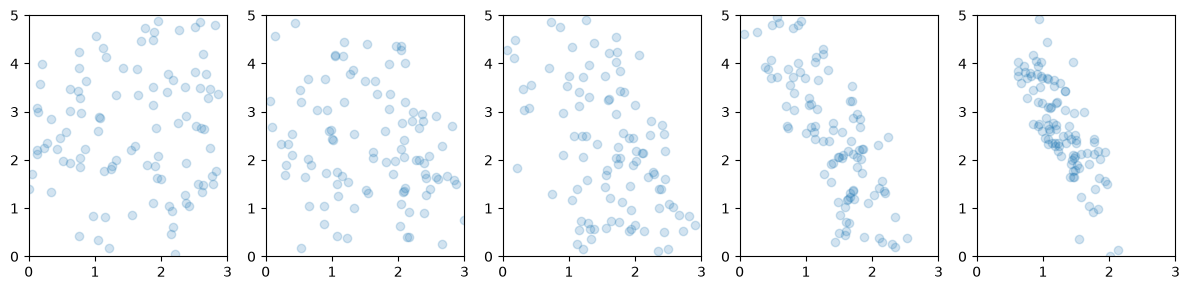

In [8]:
gradient = Unknown(
    id='grad',
    lower=0,
    upper=3,
    prior=UniformPrior(0, 3)
)

intercept = Unknown(
    id='inter',
    lower=0,
    upper=5,
    prior=UniformPrior(0, 5)
)

sigma = Unknown(
    id='inter',
    lower=0,
    upper=5,
    prior=UniformPrior(0, 5)
)

unknowns = [gradient, intercept, sigma]

abc = ABC(
        n_particles=100,
        quantile=0.5,
        initial_tolerance=np.inf,
        max_attempts=1_000_000,
        covariance_method="knn",
        distance_method="scaled",
        k=20,
        rng=rng
    )

fit = abc.refine_posterior(
    objective=objective,
    unknowns=unknowns,
    n_generations=5
)

fig, axes = plt.subplots(1, 5, figsize=(12,3))

axes = axes.flatten()

for ax, res in zip(axes, fit):
    ax.scatter(res.population.particles[:, 0], res.population.particles[:, 1], alpha=0.2)
    ax.set_xlim(0, 3)
    ax.set_ylim(0, 5)
plt.tight_layout()
plt.show()

## Nearest neighbour covariance

### Mahalanobis distance

Generation: 0
Tolerance: inf
Accepted: 128 / 128 (100.0%)
Rejected (outside allowed limits): 0 / 128 (0.0%)
Rejected (above distance tolerance): 0 / 128 (0.0%)
ESS: 100.00000000000006
Time taken: 0.3389770984649658 seconds


Generation: 1
Tolerance: 3.7112799189441334
Accepted: 104 / 240 (43.3%)
Rejected (outside allowed limits): 80 / 240 (33.3%)
Rejected (above distance tolerance): 56 / 160 (35.0%)
ESS: 73.03497772517072
Time taken: 1.4614529609680176 seconds


Generation: 2
Tolerance: 2.5133180045540104
Accepted: 130 / 332 (39.2%)
Rejected (outside allowed limits): 76 / 332 (22.9%)
Rejected (above distance tolerance): 126 / 256 (49.2%)
ESS: 76.70434855312253
Time taken: 3.0160725116729736 seconds


Generation: 3
Tolerance: 1.7866649772676162
Accepted: 102 / 433 (23.6%)
Rejected (outside allowed limits): 113 / 433 (26.1%)
Rejected (above distance tolerance): 218 / 320 (68.1%)
ESS: 72.67874928538846
Time taken: 4.406914472579956 seconds


Generation: 4
Tolerance: 1.4530469163729705
Acc

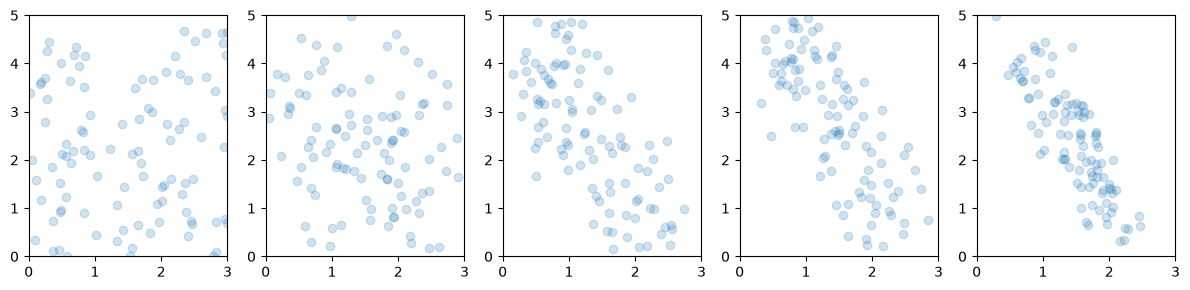

In [9]:
abc = ABC(
        n_particles=100,
        quantile=0.5,
        initial_tolerance=np.inf,
        max_attempts=1_000_000,
        covariance_method="knn",
        distance_method="mahalanobis",
        k=20,
        rng=rng
    )

fit = abc.refine_posterior(
    objective=objective,
    unknowns=unknowns,
    n_generations=5
)

fig, axes = plt.subplots(1, 5, figsize=(12,3))

axes = axes.flatten()

for ax, res in zip(axes, fit):
    ax.scatter(res.population.particles[:, 0], res.population.particles[:, 1], alpha=0.2)
    ax.set_xlim(0, 3)
    ax.set_ylim(0, 5)
plt.tight_layout()
plt.show()